[Open in Colab](https://colab.research.google.com/github/loem-ms/programming-for-information-systems-site/blob/main/content/downloads/Week_09.ipynb) · [Download notebook](/downloads/Week_09.ipynb) · [Optional ZIP](/downloads/Week_09.zip)

**Before editing:** File → Save a copy in Drive.


# Week 09 · Functions, filters and assertions


(week-09-start)=
[Session 1](#week-09-session-1) · [Session 2](#week-09-session-2) · [Session 3](#week-09-project-studio)



(week-09-session-1)=
## Session 1 · Python foundations


### A precise question

“Enabled and unfinished” differs from “unpublished.” A finished task may still be unpublished.

```python
row = {"enabled": True, "finished": True, "published": False}
print(not row["finished"], not row["published"])  # False True
```


### A predicate

A predicate returns True or False. These examples assume the required fields exist and contain Booleans.

```python
def needs_work(row):
    return row["enabled"] and not row["finished"]
```


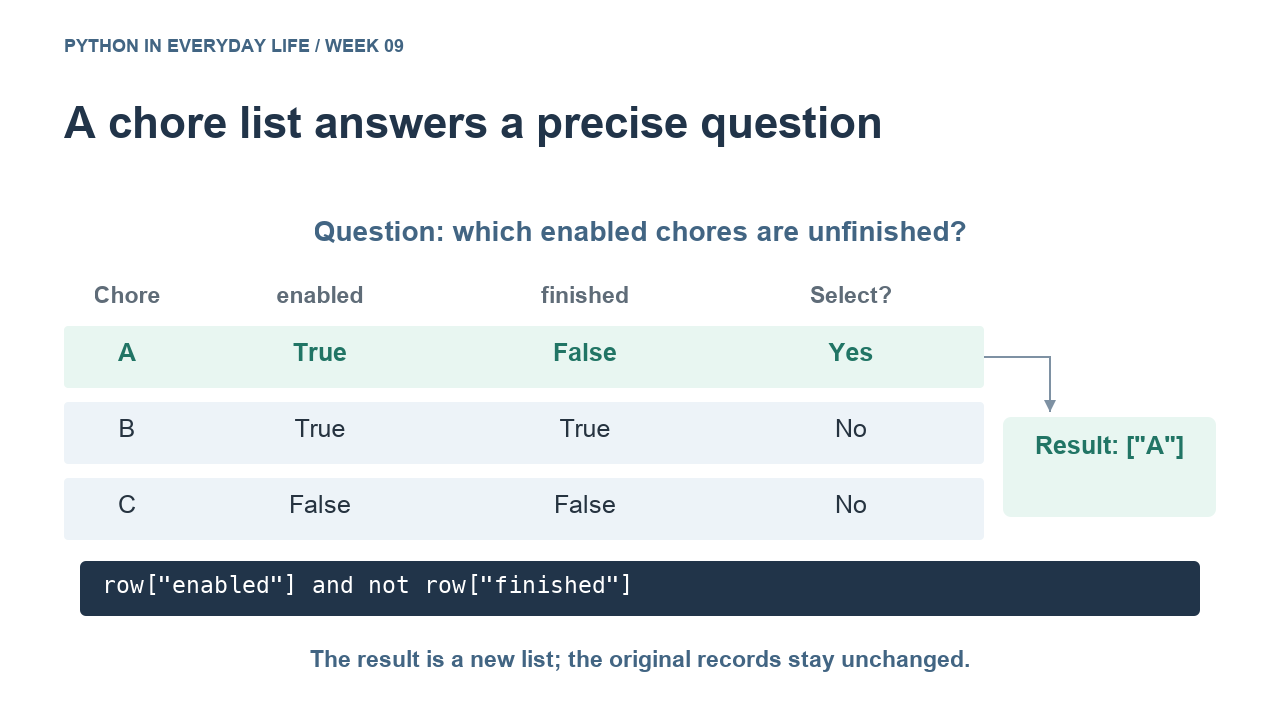


### A new result list

Build a separate list while visiting inputs. Append inside the condition and return after the loop. Removing items from the input while looping can skip records.

```python
selected = []
selected.append("A")
```


### An optional comprehension

A comprehension is a shorter form of a loop that builds a list. Preserve input order unless the contract asks for sorting.

```python
numbers = [1, 2, 3]
print([number for number in numbers if number >= 2])  # [2, 3]
```


### Independent tests

Choose expected IDs from the requirement, not by repeating the implementation. Include empty inputs and cases that distinguish plausible wrong conditions.

```python
actual = ["A"]
assert actual == ["A"]  # The expectation came from the stated rule.
```


### Checking for unwanted mutation

Two names can refer to the same list. deepcopy makes an independent snapshot, including nested records. Compare it after the function runs.

```python
import copy
records = [{"points": 1}]
before = copy.deepcopy(records)
```


### Example 1 · Make one predicate from one record

A predicate returns a Boolean. Use a single dictionary before filtering a whole list. Here finished is false and enabled is true, so predict True. published is irrelevant to the stated question.


In [ ]:
def needs_work(row):
    return row["enabled"] and not row["finished"]

row = {"enabled": True, "finished": False, "published": False}
print(needs_work(row))
assert needs_work(row) is True


### Example 2 · Build a new result instead of changing input

Start with plain numbers so the selection operation is visible without records. The loop visits every input but appends only matching values. Predict [2, 3], then the unchanged original list. The worked example next transfers this pattern to dictionaries.


In [ ]:
numbers = [1, 2, 3]
selected = []
for number in numbers:
    if number >= 2:
        selected.append(number)
print(selected)
print(numbers)
assert numbers == [1, 2, 3]


### Example 3 · Keep an independent before snapshot

A second name such as alias still refers to the original object. deepcopy makes an independent copy, including dictionaries inside a list. Predict 9 for alias, 1 for before. This is test support, not a new feature to build.


In [ ]:
import copy
records = [{"points": 1}]
alias = records
before = copy.deepcopy(records)
records[0]["points"] = 9
print(alias[0]["points"], before[0]["points"])
assert before == [{"points": 1}]


### Combined example


In [ ]:
tasks = [
    {"task_id": "A", "enabled": True, "finished": False, "published": False},
    {"task_id": "B", "enabled": True, "finished": True, "published": False},
    {"task_id": "C", "enabled": False, "finished": False, "published": False},
]
selected = []
for row in tasks:
    wanted = row["enabled"] and not row["finished"]
    print(row["task_id"], wanted, "Unpublished:", not row["published"])
    if wanted:
        selected.append(row["task_id"])
print("Selected:", selected)
assert selected == ["A"]


The selection predicate is True, False, False for A, B, C, so selected is ["A"]. All three are unpublished, demonstrating why that other field cannot answer the stated question. B tests the finished condition and C tests enabled.


(week-09-session-2)=
## Session 2 · Hands-on practice

(week-09-practice-week-09)=
Five exercises: P1–P3 are core; P4–P5 are optional. Record an expected result, observed result and explanation for each completed exercise.


### Supplied practice records · run before P1

P1, P2 and P3 use the same four records below. This cell supplies data only; write each solution in its blank work cell. T11 awaits collection. T12 is collected but not delivered. T13 is not reserved. T14 is already delivered. Each flag is a valid Boolean. These examples do not prescribe your final-project feature.


In [ ]:
records = [
    {"request_id": "T11", "reserved": True, "collected": False, "delivered": False},
    {"request_id": "T12", "reserved": True, "collected": True, "delivered": False},
    {"request_id": "T13", "reserved": False, "collected": False, "delivered": False},
    {"request_id": "T14", "reserved": True, "collected": True, "delivered": True},
]


### P1 · Collect IDs with a loop

**Core**

Easy. From the supplied practice-record cell immediately above, write a loop that appends every request_id to a new list named ids. Predict the four IDs in order. Hint: initialize the result before the loop and append inside it. Assert the complete expected list. Do not change the records.


In [ ]:
# Write your code here. Predict before running.


**Expected:** …  **Observed:** …  **Explanation:** …


### P2 · Write the selection predicate

**Core**

Easy. Write needs_collection(row) returning True only when reserved is True and collected is False. Fields in this fixture are valid Booleans. Predict True, False, False, False for the four records and write assertions. Hint: combine the two relevant fields; delivered is not part of this question.

In [ ]:
# Write your code here. Predict before running.


**Expected:** …  **Observed:** …  **Explanation:** …


### P3 · Build and test the report helper

**Core**

Core build. Write awaiting_collection(records), returning matching IDs in input order. Use an ordinary loop, a condition, append and return. Independently write expectations for the full fixture (["T11"]), empty input ([]), and two pending records (["T11","T15"]). Add T15 as a new dict rather than modifying T12. For unchanged-input evidence, first import copy, then save before = copy.deepcopy(records). After calling your helper, assert records == before. A deep copy keeps an independent snapshot; before = records would only create another name for the same list. Explain why T12 catches not-delivered filtering and T13 catches a missing reservation condition.


In [ ]:
records = [
    {"request_id": "T11", "reserved": True, "collected": False, "delivered": False},
    {"request_id": "T12", "reserved": True, "collected": True, "delivered": False},
    {"request_id": "T13", "reserved": False, "collected": False, "delivered": False},
    {"request_id": "T14", "reserved": True, "collected": True, "delivered": True},
]

def awaiting_collection(records):
    # Build and return a new list. Leave source records unchanged.
    raise NotImplementedError

# Write your expectations and tests before running the function.


**Expected:** …  **Observed:** …  **Explanation:** …


### P4 · Write a reusable regression check

**Optional**

Write check_report(select_function) that calls a supplied function on your fixture and on [], asserting ["T11"] and [] respectively. Run it against your correct helper. Then write a deliberately wrong helper that selects not delivered and show that your test raises AssertionError. Catch that error only around the deliberate wrong version and keep the passing correct version.

In [ ]:
records = [
    {"request_id": "T11", "reserved": True, "collected": False, "delivered": False},
    {"request_id": "T12", "reserved": True, "collected": True, "delivered": False},
    {"request_id": "T13", "reserved": False, "collected": False, "delivered": False},
    {"request_id": "T14", "reserved": True, "collected": True, "delivered": True},
]

# Reuse awaiting_collection. Write check_report and the deliberate wrong copy.


**Expected:** …  **Observed:** …  **Explanation:** …


### P5 · Write unittest cases

**Optional**

Write a unittest.TestCase class with separate methods for empty input, the distinguishing T12 record, and unchanged source records. Use assertEqual and copy.deepcopy. Run with TextTestRunner against an explicitly loaded suite so notebook arguments do not interfere. Use the supplied unittest reference only for runner syntax. No new feature is required.

In [ ]:
import unittest
import copy
# Reuse records and awaiting_collection.
# Write your TestCase and explicit suite/runner below.


**Expected:** …  **Observed:** …  **Explanation:** …


Optional: express your correct loop as a comprehension and run the same tests against both. Prefer the version you can explain clearly; do not expand the approved project scope.


(week-09-project-studio)=
## Session 3 · Project studio


### Project files

Run this collapsed cell once, and again after a runtime restart. No ZIP, upload or network download is needed. Existing support files are preserved. Save created or edited files separately.


In [ ]:
# @title Prepare the course files (run after each runtime restart)
# Supplied programs, starter policy, CSV fixtures and diagrams are embedded here.
# This cell uses only Python's standard library. It makes no network request.
import base64 as _course_base64
import hashlib as _course_hashlib
import json as _course_json
import os as _course_os
from pathlib import Path as _CoursePath
import zlib as _course_zlib

_course_payload = '...'
_course_raw = _course_zlib.decompress(_course_base64.b64decode(_course_payload))
if _course_hashlib.sha256(_course_raw).hexdigest() != 'd65afb5af0c0635c653e2b0ceec8a996bb34ea700651c28a762ef675a914b33e':
    raise ValueError("Embedded course files are damaged; get a fresh notebook.")
_course_files = _course_json.loads(_course_raw)
_course_key = 'week_09_d65afb5af0c0'
_course_roots = globals().setdefault("_course_workspace_roots", {})
if _course_key in _course_roots:
    _course_root = _CoursePath(_course_roots[_course_key])
elif all((_CoursePath.cwd() / _name).is_file() for _name in _course_files):
    # A complete extracted offline pack can be used in place.
    _course_root = _CoursePath.cwd()
else:
    _course_root = _CoursePath.cwd() / ".course_files" / _course_key
if _course_root.is_symlink() or any(_p.is_symlink() for _p in _course_root.parents):
    raise ValueError("Refusing a symbolic link in the course workspace")
_course_root.mkdir(parents=True, exist_ok=True)
for _name, _encoded in _course_files.items():
    _relative = _CoursePath(_name)
    if _relative.is_absolute() or ".." in _relative.parts:
        raise ValueError("Unsafe embedded support path")
    _target = _course_root / _relative
    if _target.is_symlink() or any(_p.is_symlink() for _p in _target.parents):
        raise ValueError("Refusing a symbolic link in the course workspace")
    _target.parent.mkdir(parents=True, exist_ok=True)
    if _target.exists() and not _target.is_file():
        raise ValueError("Course support path is not a regular file: " + str(_target))
    if not _target.exists():
        with _target.open("xb") as _output:
            _output.write(_course_base64.b64decode(_encoded))
_course_workspace_roots[_course_key] = str(_course_root.resolve())
_course_os.chdir(_course_root)
print("Course files ready:", _CoursePath.cwd())
print("Existing files were kept. Rerunning setup never replaces your edits.")
print("Save your notebook and download created/edited files before the runtime ends.")


### The people’s task this week

**Someone needs help:** A volunteer needs to trust and reproduce the supplied result.

**Your small part:** Run the supplied baseline, compare results and complete your notes.

![Week 9: the person’s need, your task, and the useful result.](assets/diagrams/course_week_09.svg)

**Picture one example:** A clean run shows the same planning totals and event evidence.

**A useful result:** A volunteer can repeat the result and understand its limits.

Use the supplied starting files and the task instructions below. The diagram explains the purpose; it adds no separate assignment.

**Final-project connection:** Reproduce the supplied baseline and explain its results before doing anything extra. Complete the requested notes, checks and peer record. An improvement proposal, code change or form is optional.


In [ ]:
# @title Show this lesson’s embedded diagram(s)
try:
    from IPython.display import SVG, display
except ImportError:
    print("Diagrams are in assets/diagrams; Jupyter or Colab displays them below.")
else:
    display(SVG(filename='assets/diagrams/course_week_09.svg'))


### Project context

The fictional records distinguish planning, reservation, collection and delivery. Reproduce the supplied baseline and explain those meanings. No code change is required for the minimum final project.

### Understand the system before changing it

The coordinator can distinguish a reservation from a collection and a delivery. Your minimum project is to run the supplied system, compare expected and observed results, and complete the requested written responses. You do not need to design a new feature.

**Let's think:** name one user, the input they provide, the processing step and the output they read. What can that output establish, and what still requires a person?

**Optional improvement:** after reproduction is complete, you may propose or implement one small change. The diagram below describes that optional route. Preserve human review, declared units and lifecycle evidence.

![Optional improvement route: agree expected examples, implement a small change and inspect test evidence.](assets/diagrams/w09_change.svg)

In [ ]:
# @title Show this lesson’s embedded diagram(s)
try:
    from IPython.display import SVG, display
except ImportError:
    print("Diagrams are in assets/diagrams; Jupyter or Colab displays them below.")
else:
    display(SVG(filename='assets/diagrams/w09_change.svg'))


### Agree on expected results

Use the supplied fixture to write two expected outcomes before running. Record the observed results and explain any difference. A separate change request is needed only if you choose an optional improvement.

### Minimum project and optional improvement

**Required minimum:** reproduce the supplied system and tests, explain the results in your own words and fill every requested response/note. Keep a clean-run record and the peer/handoff evidence. Copying output without explaining it is not the whole task.

**Optional:** propose a small improvement, or implement an approved one in a separate copy. A read-only report, one validation field or a clearer message can be enough. For any change you make, state inputs, outputs, a boundary/failure case and one behavior that must stay unchanged. An unchanged baseline is a valid minimum submission.

### Reproduce first; change only if you choose

Run the supplied baseline from its documented starting point. Keep the resulting observations and requested notes. If you choose an optional Python or SQL change, preserve a clean baseline and compare independent expected results before and after.

### 3. Establish the actual baseline

Load the authoritative CSVs and the complete supplied reservation/event engine. A new database is created each run. Headers, line snapshots and availability commit together; a failed later batch rolls back earlier changes. Events are whole-reservation observations and require collection before delivery. Do not add an event to a held or rejected request.

**Before running the next cells:** inspect the three fixture CSVs and write expected outcomes for all six pickup requests. Keep those predictions so you can compare them with the printed results.

In [ ]:
from pathlib import Path
import csv

def fixture_directory():
    for candidate in (Path("final-data"), Path("learning_materials/final-data"), Path("../learning_materials/final-data")):
        if (candidate / "offer_batches.csv").is_file():
            return candidate.resolve()
    raise FileNotFoundError("Keep learning_materials/final-data with the teaching materials")

DATA_DIR = fixture_directory()

def read_fixture():
    with (DATA_DIR / "offer_batches.csv").open(encoding="utf-8", newline="") as file:
        batches = [(row["batch_id"], row["description"], int(row["portions_per_container"]),
                    int(row["opening_available"])) for row in csv.DictReader(file)]
    grouped = {}
    with (DATA_DIR / "pickup_requests.csv").open(encoding="utf-8", newline="") as file:
        for row in csv.DictReader(file):
            if row["reviewed"] not in ("yes", "no"):
                raise ValueError("reviewed must be yes or no")
            reviewed = row["reviewed"] == "yes"
            request = grouped.setdefault(row["request_id"], {"reviewed": reviewed, "lines": []})
            if request["reviewed"] != reviewed:
                raise ValueError("conflicting review flags within one request")
            request["lines"].append((row["batch_id"], int(row["containers"])))
    requests = [(request_id, item["reviewed"], item["lines"])
                for request_id, item in grouped.items()]
    with (DATA_DIR / "rescue_events.csv").open(encoding="utf-8", newline="") as file:
        events = [(row["request_id"], row["event_type"]) for row in csv.DictReader(file)]
    return batches, requests, events

batches, requests, events = read_fixture()
print("Fixture:", len(batches), "batches;", len(requests), "requests;", len(events), "events")

### Supplied setup: run once, then continue

**No editing required in the engine below.** Run the fixture-loading cell above, then run this supplied engine cell to create the known starting database. Rerunning it resets the fixture; it does not retry an operation against the previous state.

The implementation may be collapsed by your notebook viewer. You may inspect it later, but your task is the behavior requested next. After setup, [continue to your project task](#week-09-project-task).

In [ ]:
import sqlite3

def pickup_label(total_portions, reviewed):
    if type(total_portions) is not int or total_portions < 0 or type(reviewed) is not bool:
        raise ValueError("expected nonnegative integer portions and a Boolean review flag")
    if not reviewed:
        return "hold"
    return "team" if total_portions >= 20 else "standard"

def new_rescue_db(batch_rows):
    db = sqlite3.connect(":memory:")
    db.execute("PRAGMA foreign_keys=ON")
    db.executescript("""
        CREATE TABLE batches(
            batch_id TEXT PRIMARY KEY, description TEXT,
            portions_per_container INTEGER CHECK(portions_per_container>0),
            opening_available INTEGER CHECK(opening_available>=0),
            available INTEGER CHECK(available>=0));
        CREATE TABLE reservations(
            request_id TEXT PRIMARY KEY, reviewed INTEGER CHECK(reviewed=1),
            label TEXT, planned_portions INTEGER CHECK(planned_portions>0));
        CREATE TABLE reservation_lines(
            request_id TEXT REFERENCES reservations(request_id), line_no INTEGER,
            batch_id TEXT REFERENCES batches(batch_id), containers INTEGER CHECK(containers>0),
            portions_per_container INTEGER CHECK(portions_per_container>0),
            PRIMARY KEY(request_id,line_no));
        CREATE TABLE events(
            request_id TEXT REFERENCES reservations(request_id),
            event_type TEXT CHECK(event_type IN ('collected','delivered')),
            PRIMARY KEY(request_id,event_type));
    """)
    with db:
        for batch_id, description, portions, available in batch_rows:
            if type(portions) is not int or portions <= 0 or type(available) is not int or available < 0:
                raise ValueError("invalid batch planning counts")
            db.execute("INSERT INTO batches VALUES (?,?,?,?,?)",
                       (batch_id, description, portions, available, available))
    return db

def reserve(db, request_id, reviewed, lines, inject_failure=False):
    if type(reviewed) is not bool or not reviewed:
        raise ValueError("coordinator review required")
    if not lines or any(type(count) is not int or count <= 0 for batch, count in lines):
        raise ValueError("reservation needs positive whole container counts")
    with db:
        prepared = []
        for batch_id, containers in lines:
            batch = db.execute("SELECT portions_per_container FROM batches WHERE batch_id=?",
                               (batch_id,)).fetchone()
            if batch is None:
                raise ValueError(f"unknown batch {batch_id}")
            prepared.append((batch_id, containers, batch[0]))
        total = sum(containers * portions for batch_id, containers, portions in prepared)
        label = pickup_label(total, reviewed)
        db.execute("INSERT INTO reservations VALUES (?,?,?,?)", (request_id, 1, label, total))
        for index, (batch_id, containers, portions) in enumerate(prepared, start=1):
            change = db.execute("UPDATE batches SET available=available-? WHERE batch_id=? AND available>=?",
                                (containers, batch_id, containers))
            if change.rowcount != 1:
                raise ValueError(f"insufficient available containers for {batch_id}")
            db.execute("INSERT INTO reservation_lines VALUES (?,?,?,?,?)",
                       (request_id, index, batch_id, containers, portions))
            if inject_failure and index == 1:
                raise RuntimeError("deliberate failure after first reservation line")
    return label

def record_event(db, request_id, event_type):
    if event_type not in ("collected", "delivered"):
        raise ValueError("unknown event type")
    with db:
        if db.execute("SELECT 1 FROM reservations WHERE request_id=?", (request_id,)).fetchone() is None:
            raise ValueError("event needs an accepted reservation")
        if event_type == "delivered" and db.execute(
            "SELECT 1 FROM events WHERE request_id=? AND event_type='collected'", (request_id,)
        ).fetchone() is None:
            raise ValueError("record collection before delivery")
        db.execute("INSERT INTO events VALUES (?,?)", (request_id, event_type))

def snapshot(db):
    # Table names are fixed teaching constants, never user-supplied SQL.
    return tuple(tuple(db.execute(f"SELECT * FROM {table} ORDER BY 1,2").fetchall())
                 for table in ("batches", "reservations", "reservation_lines", "events"))

def build_fixture(batch_rows, request_rows, event_rows):
    db = new_rescue_db(batch_rows)
    decisions = []
    for request_id, reviewed, lines in request_rows:
        before = snapshot(db)
        try:
            label = reserve(db, request_id, reviewed, lines)
        except ValueError as error:
            assert snapshot(db) == before
            decisions.append((request_id, "held" if not reviewed else "rejected", str(error)))
        else:
            decisions.append((request_id, "accepted", label))
    for request_id, event_type in event_rows:
        record_event(db, request_id, event_type)
    return db, decisions

# Rerunning this cell starts a new database; it does not retry against old state.
if "rescue_db" in globals():
    rescue_db.close()
rescue_db, decisions = build_fixture(batches, requests, events)
print("Reservation decisions:", decisions)


(week-09-project-task)=
### Your turn

**Required minimum:** run the supplied baseline and its checks. Compare the six request outcomes with your predictions. Record the offered/reserved/collected/delivered planning portions, batch totals and current availability. Explain the demonstrated unchanged state after an unreviewed request or a later-line shortage, and the event-order checks. Complete all requested response/note cells, and keep one peer observation plus your response or clarified run guide.

**Optional extension:** propose an improvement, or use the blank project cells/a separate module to implement one. Only if you change code, show its changed result, one preserved behavior, a boundary/failure case and an unchanged snapshot for a read-only feature. Do not mark an unused optional work cell as unfinished required work.

In [ ]:
# Write your implementation and evidence here. Add cells as needed.

### 4. Separate the rule, command and tests

A `.py` module can hold your function/query; an entry point obtains inputs and displays results; tests import the function without launching the application. Use `if __name__ == "__main__":` for startup. The supplied [pickup_app.py](https://loem-ms.github.io/programming-for-information-systems-site/learning_materials/programs/pickup_app.py) and [rescue_cli.py](https://loem-ms.github.io/programming-for-information-systems-site/learning_materials/programs/rescue_cli.py) demonstrate this with a planning calculation, not the full reservation system.

From `learning_materials/` in a terminal:

**Choose the course interpreter.** In terminal examples, `python` means the Python used for your course environment. If setup created `.venv`, replace it with the operating-system-specific path in the [program guide](https://loem-ms.github.io/programming-for-information-systems-site/content/learning-materials/programs/readme/#choose-the-course-interpreter). That path changes when you change directories. In a notebook, `import sys; print(sys.executable)` shows the interpreter in use.

```text
python programs/rescue_cli.py --containers 3
python -m unittest discover -s programs -p "test_*.py"
```

With the default three declared portions per container, three containers plan nine portions. That is not delivery evidence. The discovery command tests supplied practice modules, not your own project automatically. Provide the command and working directory that actually test your change. If using an optional project scaffold, replace TODOs and skipped checks before claiming completed behavior.

### Peer reproduction check

Exchange the clean starting data, run instructions and two expected outcomes. The peer runs the supplied baseline and records what happened. Clarify a confusing instruction and rerun, or explain why no revision was needed. If you made an optional change, test that separately.

### Your turn

Give a peer the supplied starting fixture, actual run command/cells, two expected outcomes and one invariant. Record one observed finding and your response, including a retest. Individually explain one design judgment and one limitation. If working alone before class, label your self-review as rehearsal, not real peer evidence.

In [ ]:
# Write your implementation and evidence here. Add cells as needed.

### Handoff preparation for Week 10

**Offline reading card · A volunteer retries a job.** A volunteer loses the confirmation after reserving containers and repeats the request. A handoff note should identify the request ID, starting state, attempted action, observed result and recovery. Duplicate reservation IDs and duplicate event records need a deliberate response; neither should silently debit availability again.

There is no new research assignment. Use the supplied case to improve the project handoff: record the starting state, attempted action, observed result, recovery step and one check that would help a new coordinator trust the system.

**Handoff preparation time:** included in the Week 10 project estimate; this is not a seventh research assignment.

[Optional further reading (English)](https://sre.google/sre-book/postmortem-culture/)

### Optional supplied project references

These original examples explain the project application. Consult the reference you need; they are not extra Python core exercises.

### A function patch and independent test cases

The short example compares a strict comparison (`>`) with an inclusive one (`>=`). A Boolean gate returns before that comparison. The examples use project-flavored names to show general function control flow and regression checks.

In [ ]:
def before_label(total_portions, reviewed):
    if not reviewed:
        return "hold"
    return "team" if total_portions > 20 else "standard"  # Deliberate boundary mistake.

def after_label(total_portions, reviewed):
    if not reviewed:
        return "hold"
    return "team" if total_portions >= 20 else "standard"

for portions, reviewed, expected in [(19,True,"standard"),(20,True,"team"),(21,True,"team"),(20,False,"hold")]:
    print(portions,reviewed,before_label(portions,reviewed),after_label(portions,reviewed))
    assert after_label(portions,reviewed)==expected
assert before_label(20,True)!="team"
# Controlled inputs here are nonnegative integer planning counts and Boolean review flags.

Only the exact-boundary case changes when `>` becomes `>=`; the unreviewed case stays held. A small patch needs a stated rule and a case that distinguishes it from the old behavior. The general boundary practice is in Session 2 above.

### Select records with the intended predicate

A list comprehension can filter records using more than one Boolean field. The example distinguishes `not collected` from `not delivered`; these predicates select different records.

In [ ]:
def awaiting_collection(records):
    return [row["request_id"] for row in records if row["reserved"] and not row["collected"]]

records = [
 {"request_id":"D10","reserved":True,"collected":False,"delivered":False},
 {"request_id":"D11","reserved":True,"collected":True,"delivered":False},
 {"request_id":"D12","reserved":True,"collected":True,"delivered":True},
]
assert awaiting_collection(records)==["D10"]
# A plausible wrong query confuses collection follow-up with delivery follow-up.
wrong = [row["request_id"] for row in records if row["reserved"] and not row["delivered"]]
assert wrong==["D10","D11"]
print("Correct collection view:",awaiting_collection(records),"Wrong-stage view:",wrong)

D11 distinguishes the two filters: its collection field is True while its delivery field is False. Read each predicate explicitly before interpreting the returned list. The general Boolean-filter practice is in Session 2 above.


(week-09-finish)=
### Finish: check, save and decide what comes next

- [ ] I can explain the Python concept used this week.
- [ ] I kept a prediction, an observed result and an explanation for the core practice.
- [ ] I completed the required project behavior and checks described above.
- [ ] I recorded one peer observation or individual finding, plus a revision or defended decision.
- [ ] I stated one limitation or question that requires a person.

**Save:** save this notebook and any project files you changed. Keep a separate backup. Re-run the relevant completed cells from a known starting state before claiming the result; unresolved required TODOs or failed required tests need an honest note. Unused optional improvement cells may stay untouched. Send assessed work to [submit.progmis@gmail.com](mailto:submit.progmis@gmail.com); exact deadlines and file names remain separately announced.

**Stop point:** when the required practice and project evidence are complete, save and stop. Optional follow-ups can wait.

**Next:** Week 10: reproduce the baseline from clean data and hand over the run guide.

[Back to Start Here](#week-09-start) · [Review the Python explanation](#week-09-session-1) · [Return to Project Studio](#week-09-project-studio)